# Лабораторная работа № 3. Кластеризация
**Цель:** изучить методы кластеризации, оценить качество разбиения и интерпретировать выделенные группы.

**Датасет:** `caffeine_crash_and_anxiety_telemetry.csv` — характеристики потребления кофеина и реакции организма. Методы: K-means и иерархическая кластеризация Ward.

Для запуска поместить CSV рядом с ноутбуком. Используются pandas, numpy, scipy, scikit-learn, matplotlib, seaborn. Источник и способ получения данных не подтверждены; результаты относятся к данной выборке, а не к медицинским закономерностям.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import shapiro, gaussian_kde
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score, normalized_mutual_info_score, pairwise_distances)
from sklearn.metrics.cluster import contingency_matrix
from threadpoolctl import threadpool_limits
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
threadpool_limits(limits=2)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)

## 1. Загрузка и дескриптивный анализ
Проверим размерность, типы признаков, пропуски, дубликаты, разнообразие и распределения.

In [2]:
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')
print('Размерность:', df.shape)
print('Полных дубликатов:', df.duplicated().sum())
print('Повторяющихся ID:', df.user_id.duplicated().sum())
display(df.head())
display(pd.DataFrame({'Тип':df.dtypes.astype(str), 'Пропуски':df.isna().sum(), 'Уникальных':df.nunique()}))
num = df.select_dtypes(include='number').columns.tolist()
cat = df.select_dtypes(exclude='number').columns.tolist()
print('Числовых:',len(num), 'Нечисловых:',len(cat))
display(df[num].describe().T)
for col in cat:
    if col != 'user_id':
        display(df[col].value_counts().rename('Количество').to_frame())

Размерность: (8000, 18)
Полных дубликатов: 0
Повторяющихся ID: 0


,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


,Тип,Пропуски,Уникальных
user_id,object,0,8000
age,int64,0,48
gender,object,0,3
cyp1a2_metabolizer_type,object,0,3
caffeine_tolerance,object,0,3
baseline_anxiety_score,float64,0,86
prior_sleep_hours,float64,0,64
daily_hydration_liters,float64,0,381
primary_caffeine_source,object,0,6
caffeine_mg,int64,0,375


Числовых: 12 Нечисловых: 6


,count,mean,std,min,25%,50%,75%,max
age,8000.0,32.951,11.514,18.0,24.00,30.00,40.00,65.0
baseline_anxiety_score,8000.0,3.489,2.079,1.0,1.80,3.00,4.60,9.5
prior_sleep_hours,8000.0,6.376,1.293,3.2,5.50,6.40,7.30,9.5
daily_hydration_liters,8000.0,2.108,0.784,0.6,1.56,2.11,2.65,4.8
caffeine_mg,8000.0,198.044,65.866,40.0,157.00,195.00,234.00,420.0
sugar_grams,8000.0,18.026,19.132,0.0,0.80,10.50,34.60,62.0
consumption_duration_min,8000.0,28.976,20.489,3.0,10.00,26.00,45.00,107.0
heart_rate_spike_bpm,8000.0,4.670,4.004,2.0,2.00,2.50,6.20,35.7
jitters_intensity_score,8000.0,3.323,2.310,1.0,1.30,2.70,4.50,10.0
acute_anxiety_score,8000.0,3.684,2.371,1.0,1.70,3.20,5.10,10.0


,Количество
gender,
Male,3972
Female,3797
Non-Binary,231


,Количество
cyp1a2_metabolizer_type,
Normal,3702
Fast,2660
Slow,1638


,Количество
caffeine_tolerance,
Moderate,3963
Low,2065
High,1972


,Количество
primary_caffeine_source,
Brewed Drip Coffee,2057
Energy Drink (Full Sugar),2011
Energy Drink (Sugar-Free),1741
Espresso / Specialty Drinks,1240
Pre-Workout Supplement,627
Matcha / Green Tea,324


,Количество
crash_risk_level,
Moderate Crash & Lethargy,2426
Mild Afternoon Fatigue,2377
Severe Crash & Tachycardia,2161
Sustained / Negligible Crash,1036


В выборке 8000 строк, 18 столбцов (12 числовых и 6 нечисловых, включая идентификатор и метку). Пропусков и полных дубликатов нет. Каждая строка — наблюдение с характеристиками потребителя и его реакции на кофеин.

### 1.1. Оценка распределений
Гистограммы и KDE дополним асимметрией и критерием Шапиро–Уилка на фиксированной подвыборке 1000 строк. При p < 0.05 отвергаем гипотезу нормальности; при большом объёме тест чувствителен к малым отклонениям. Нормальность для K-means и Ward не обязательна.

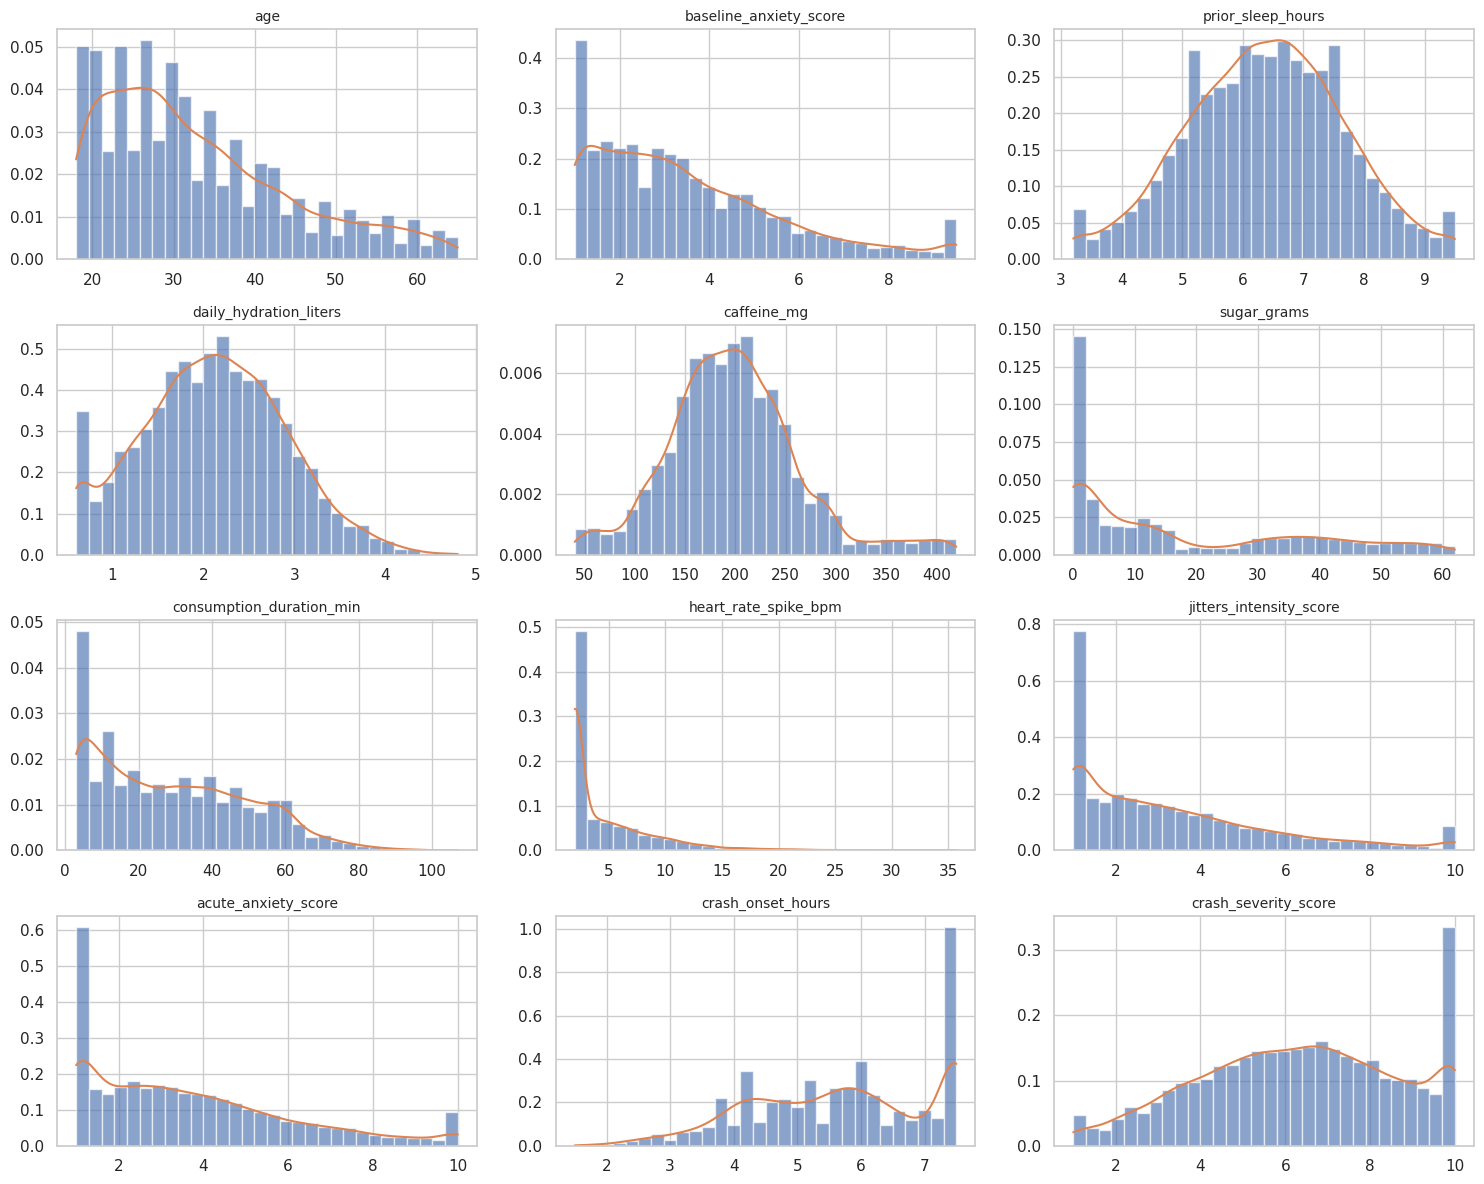

,Асимметрия,Эксцесс,W,p-value,H0 при 0.05
age,0.852,-0.049,0.9172,5.85e-23,отвергается
baseline_anxiety_score,0.987,0.476,0.8952,1.56e-25,отвергается
prior_sleep_hours,-0.039,-0.274,0.9951,2.46e-03,отвергается
daily_hydration_liters,0.117,-0.340,0.9915,1.59e-05,отвергается
caffeine_mg,0.571,1.061,0.9702,1.88e-13,отвергается
sugar_grams,0.765,-0.830,0.8477,6.24e-30,отвергается
consumption_duration_min,0.507,-0.665,0.9319,6.21e-21,отвергается
heart_rate_spike_bpm,2.089,5.579,0.7190,6.22e-38,отвергается
jitters_intensity_score,1.100,0.574,0.8824,7.54e-27,отвергается
acute_anxiety_score,0.870,0.056,0.9088,5.41e-24,отвергается


In [3]:
fig, axes = plt.subplots(4,3,figsize=(15,12))
for ax, col in zip(axes.flat,num):
    ax.hist(df[col],bins=30,density=True,alpha=.65)
    xx=np.linspace(df[col].min(),df[col].max(),200); ax.plot(xx,gaussian_kde(df[col])(xx))
    ax.set_title(col,fontsize=10); ax.set_xlabel('')
plt.tight_layout(); plt.show()
sub = df[num].sample(1000,random_state=42)
normal = pd.DataFrame({'Асимметрия':df[num].skew(), 'Эксцесс':df[num].kurt(),
    'W':sub.apply(lambda x:shapiro(x).statistic), 'p-value':sub.apply(lambda x:shapiro(x).pvalue)})
normal['H0 при 0.05'] = np.where(normal['p-value']<.05,'отвергается','не отвергается')
display(normal.style.format({'p-value':'{:.2e}','W':'{:.4f}','Асимметрия':'{:.3f}','Эксцесс':'{:.3f}'}))

**Анализ:** сон и гидратация визуально ближе к симметричным распределениям. Прирост ЧСС, дрожь и исходная тревожность имеют выраженную правую асимметрию. Сахар содержит много малых значений, время наступления спада ограничено сверху. Стандартизация меняет масштаб, но не форму распределения.

### 1.2. Информационная значимость признаков
Проверим дисперсию, число уникальных значений и корреляции Пирсона. Дисперсия в исходных единицах зависит от масштаба; корреляции отражают линейные связи, но не доказывают причинность.

,var,nunique
age,132.566,48.0
baseline_anxiety_score,4.324,86.0
prior_sleep_hours,1.671,64.0
daily_hydration_liters,0.614,381.0
caffeine_mg,4338.313,375.0
sugar_grams,366.038,617.0
consumption_duration_min,419.789,96.0
heart_rate_spike_bpm,16.036,225.0
jitters_intensity_score,5.336,91.0
acute_anxiety_score,5.620,91.0


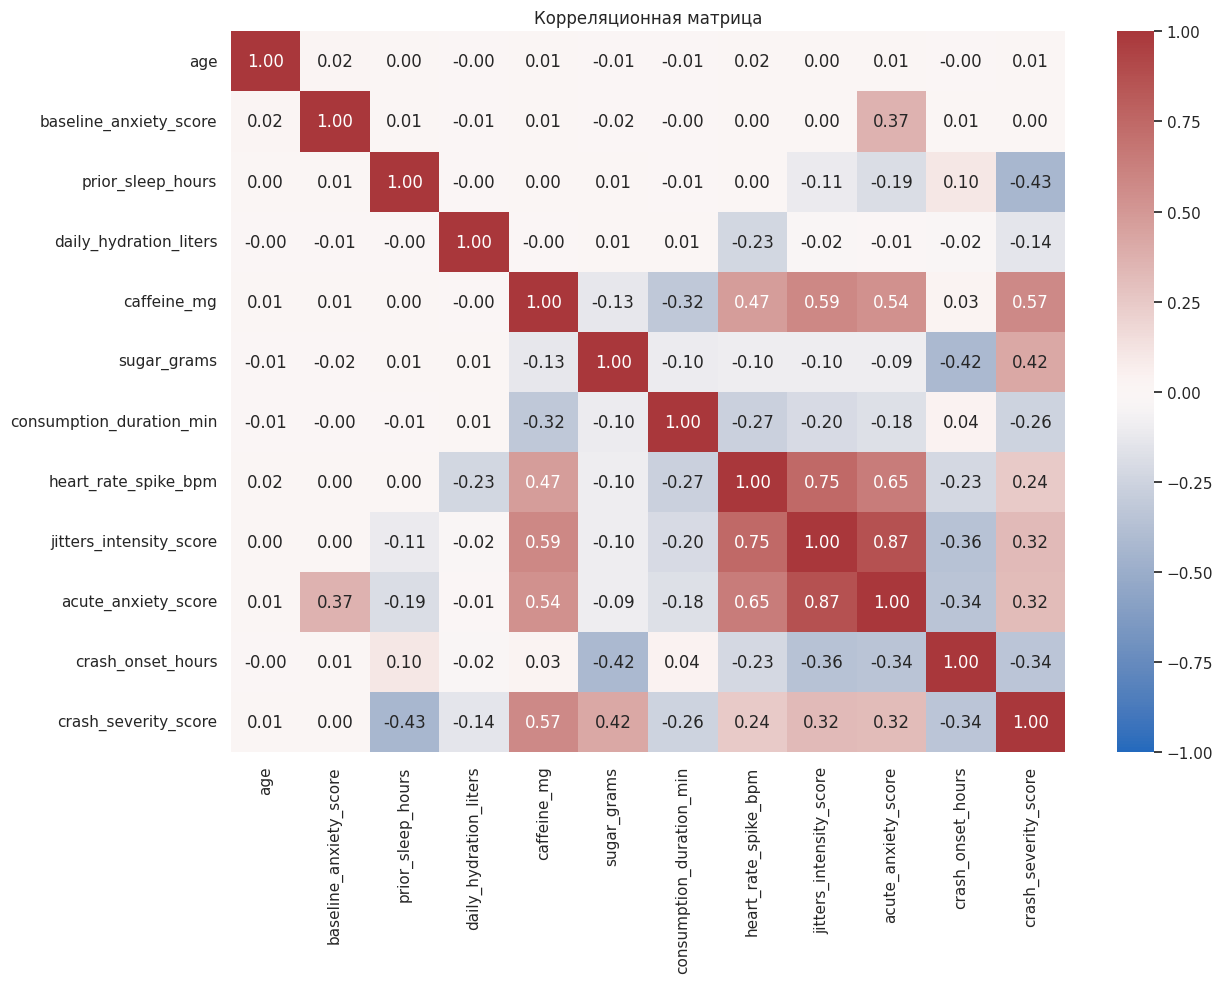

,min,max,mean,count
crash_risk_level,,,,
Sustained / Negligible Crash,1.0,3.4,2.433,1036
Mild Afternoon Fatigue,3.5,5.8,4.754,2377
Moderate Crash & Lethargy,5.9,7.9,6.874,2426
Severe Crash & Tachycardia,8.0,10.0,9.188,2161


Признаки модели: ['age', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm', 'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours']


In [4]:
display(df[num].agg(['var','nunique']).T)
plt.figure(figsize=(13,10)); sns.heatmap(df[num].corr(),annot=True,fmt='.2f',cmap='vlag',center=0,vmin=-1,vmax=1)
plt.title('Корреляционная матрица'); plt.tight_layout(); plt.show()
display(df.groupby('crash_risk_level').crash_severity_score.agg(['min','max','mean','count']).sort_values('min'))
features = [col for col in num if col!='crash_severity_score']
print('Признаки модели:',features)

**Выбор признаков:**
- `user_id` — идентификатор, не имеет смысла в метрике расстояния.
- `crash_risk_level` — существующая внешняя разметка, не используется при обучении. Диапазоны `crash_severity_score` по классам не пересекаются; тяжесть также исключаем, чтобы избежать утечки разметки.
- `gender`, `cyp1a2_metabolizer_type`, `caffeine_tolerance`, `primary_caffeine_source` — категориальные переменные. Исключаем из евклидовой модели, чтобы не вводить произвольный порядок и веса кодирования. Они остаются для описания групп.
- 11 числовых признаков характеризуют исходное состояние, потребление и реакцию. Констант нет. Сильная связь дрожи и острой тревожности (r≈0.87) означает возможное удвоение веса блока реакции; сохраняем оба как разные измеряемые эффекты. Возраст слабо коррелирует с остальными, но сохранён как потенциально полезная характеристика.

**Осмысленность:** ищем профили потребления и реакции, не пытаясь воспроизвести известные классы риска. Обучение проводится без меток; внешний класс используется только после обучения.

### 1.3. Выбросы
Правило IQR: потенциальные выбросы лежат вне [Q1−1.5 IQR; Q3+1.5 IQR], экстремальные — вне границ 3 IQR. При асимметрии умеренные крайние значения могут быть обычными наблюдениями. Удаляем только экстремальные по используемым признакам и проверим чувствительность к этому решению.

,IQR,За 1.5 IQR,За 3 IQR
age,16.00,38,0
baseline_anxiety_score,2.80,243,0
prior_sleep_hours,1.80,0,0
daily_hydration_liters,1.09,21,0
caffeine_mg,77.00,283,0
sugar_grams,33.80,0,0
consumption_duration_min,35.00,2,0
heart_rate_spike_bpm,4.20,424,96
jitters_intensity_score,3.20,228,0
acute_anxiety_score,3.40,0,0


Исключено 96 (1.20%); осталось 7904
Экстремальных значений по исходным границам после фильтрации: 0


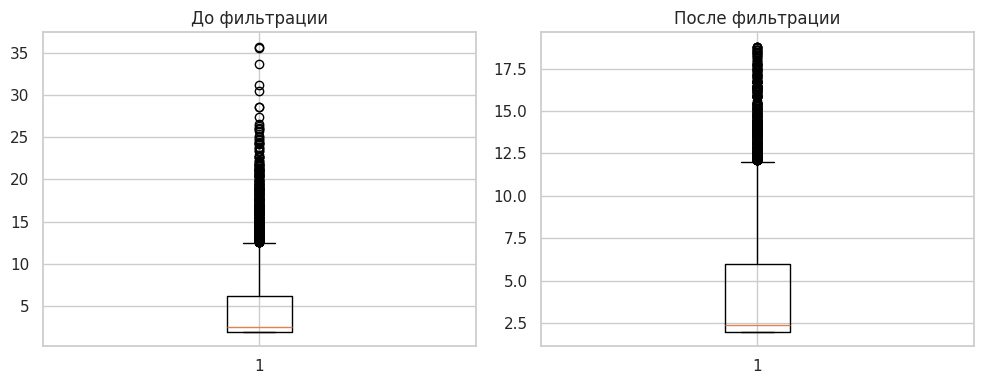

In [5]:
raw = df[features].copy()
q1,q3 = raw.quantile(.25),raw.quantile(.75)
iqr = q3-q1
flag15 = raw.lt(q1-1.5*iqr)|raw.gt(q3+1.5*iqr)
flag3 = raw.lt(q1-3*iqr)|raw.gt(q3+3*iqr)
display(pd.DataFrame({'IQR':iqr,'За 1.5 IQR':flag15.sum(),'За 3 IQR':flag3.sum()}))
keep = ~flag3.any(axis=1)
clean = df.loc[keep].reset_index(drop=True)
X = clean[features].copy(); y_true = clean.crash_risk_level
print(f'Исключено {(~keep).sum()} ({(~keep).mean():.2%}); осталось {len(X)}')
print('Экстремальных значений по исходным границам после фильтрации:',flag3.loc[keep].sum().sum())
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].boxplot(raw.heart_rate_spike_bpm); axes[0].set_title('До фильтрации')
axes[1].boxplot(X.heart_rate_spike_bpm); axes[1].set_title('После фильтрации')
plt.tight_layout(); plt.show()

**Вывод:** исключено 96 экстремальных наблюдений по приросту ЧСС. Осталось 7904 строки. Отсутствие экстремальных значений по выбранному правилу не гарантирует абсолютного отсутствия выбросов; удаление не означает, что эти измерения ошибочны. Условия для разведочной кластеризации выполнены с указанными ограничениями.

## 2. Стандартизация и структура данных
Используем StandardScaler: $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$. Среднее равно 0, стандартное отклонение (ddof=0) — 1. Иначе признаки с крупными числовыми единицами (доза, длительность) доминировали бы в евклидовом расстоянии. Min-max чувствителен к экстремумам; StandardScaler выбран после фильтрации и согласно заданию.

In [6]:
scaler=StandardScaler(); Z=scaler.fit_transform(X)
Zdf=pd.DataFrame(Z,columns=features)
display(pd.DataFrame({'Среднее до':X.mean(),'Std до':X.std(ddof=0),'Среднее после':Zdf.mean(),'Std после':Zdf.std(ddof=0)}).round(6))
assert np.allclose(Z.mean(axis=0),0) and np.allclose(Z.std(axis=0),1)

,Среднее до,Std до,Среднее после,Std после
age,32.928,11.495,0.0,1.0
baseline_anxiety_score,3.487,2.078,0.0,1.0
prior_sleep_hours,6.375,1.294,-0.0,1.0
daily_hydration_liters,2.111,0.783,-0.0,1.0
caffeine_mg,196.584,64.471,-0.0,1.0
sugar_grams,18.190,19.150,-0.0,1.0
consumption_duration_min,29.202,20.468,-0.0,1.0
heart_rate_spike_bpm,4.455,3.499,0.0,1.0
jitters_intensity_score,3.245,2.210,-0.0,1.0
acute_anxiety_score,3.612,2.292,-0.0,1.0


### 2.1. Матрица диаграмм рассеивания
Покажем шесть наиболее содержательных переменных (доза, сахар, сон, реакция) на случайной подвыборке 700 объектов для читаемости. Обучение выполняется по всем 11 признакам и всем очищенным объектам.

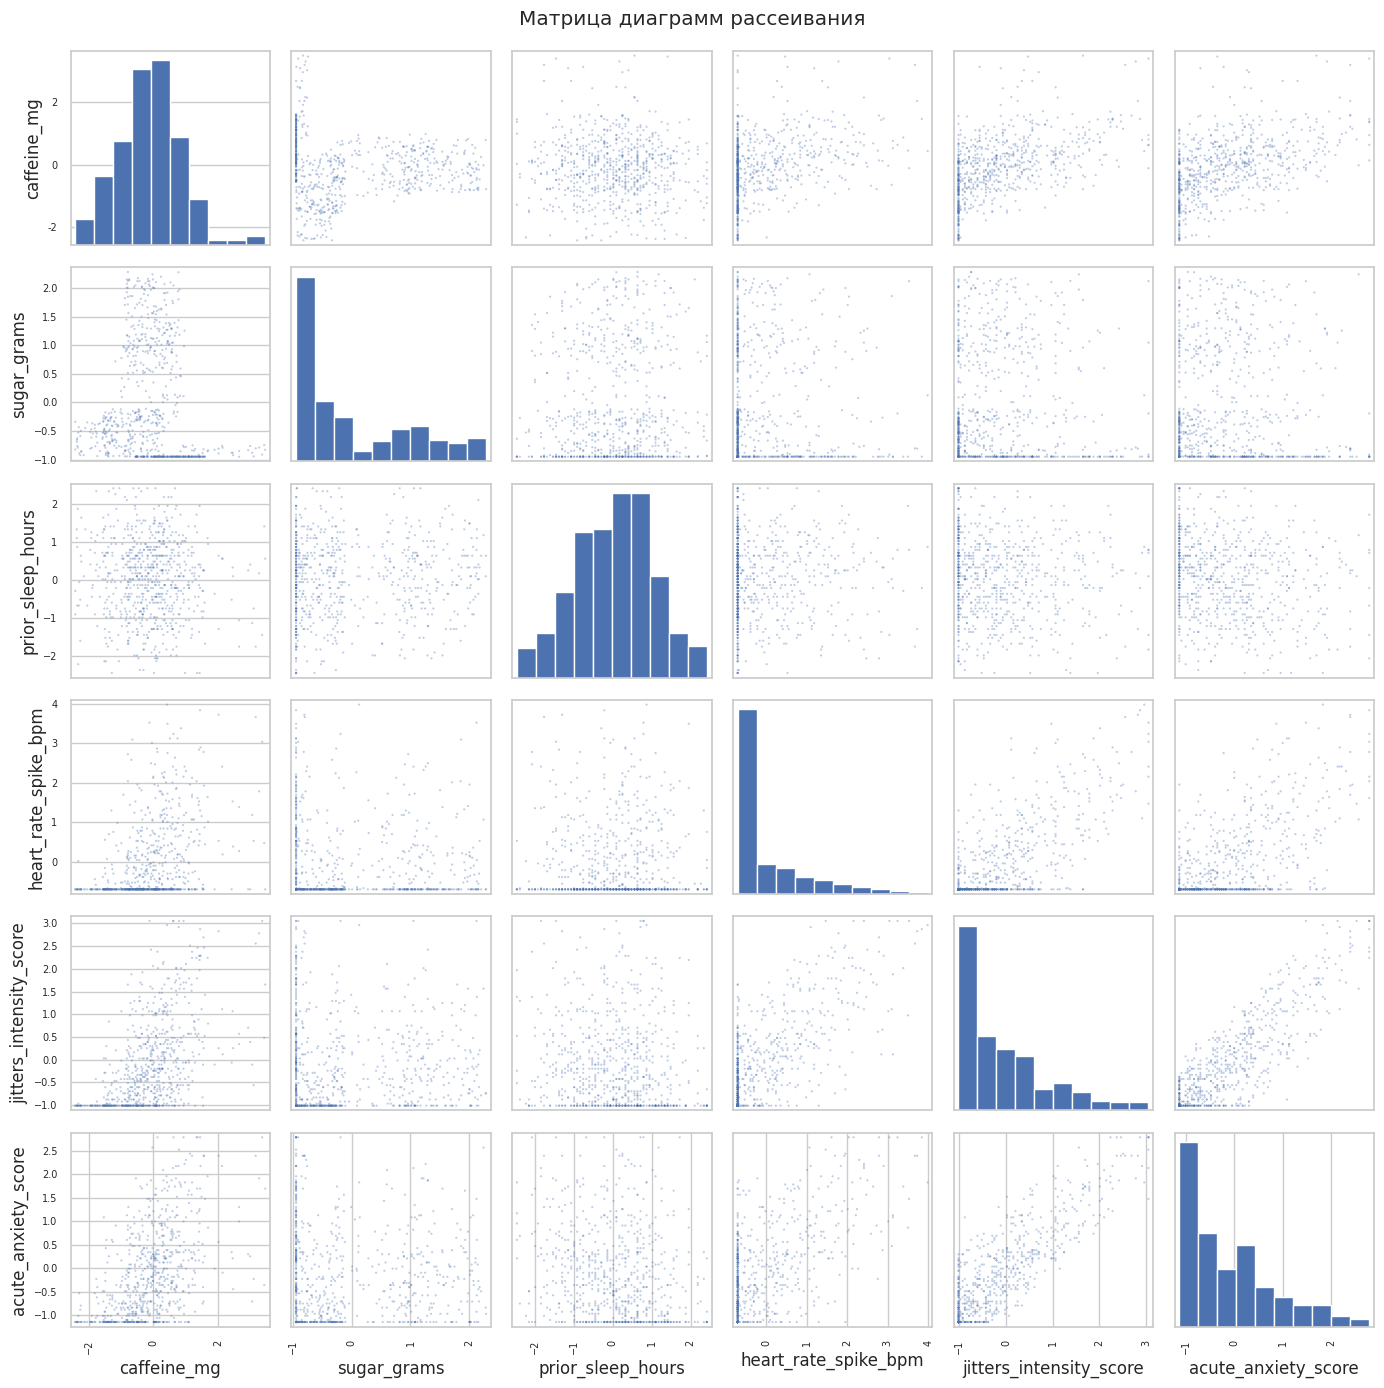

In [7]:
plot_features=['caffeine_mg','sugar_grams','prior_sleep_hours','heart_rate_spike_bpm','jitters_intensity_score','acute_anxiety_score']
sample=Zdf[plot_features].sample(700,random_state=42)
axes=pd.plotting.scatter_matrix(sample,figsize=(14,14),alpha=.35,diagonal='hist',s=10)
for ax in axes.flat: ax.tick_params(labelsize=7)
plt.suptitle('Матрица диаграмм рассеивания',y=.99); plt.tight_layout(); plt.show()

**Анализ:** облака вытянуты вдоль коррелирующих признаков реакции, наблюдаются скопления у нижних границ шкал и перекрытия. Чётких изолированных групп не видно. Предварительно возможны 2–4 широких профиля, точное число визуально установить нельзя.

**Выбор методов:** K-means минимизирует сумму квадратов расстояний до центров и проверяет гипотезу о компактных группах. Ward минимизирует прирост внутрикластерного разброса при объединении и позволяет изучить вложенную структуру. Оба метода предпочитают компактные группы, поэтому при перекрытии и вытянутых облаках ожидается невысокий силуэт. DBSCAN не выбран из-за неоднородности плотности и сложности подбора общего радиуса в 11 измерениях.

## 3. Кластеризация и подбор k
### 3.1. K-means
Метод локтя: оцениваем замедление убывания WCSS (inertia). Силуэт: сравниваем внутрикластерную близость с ближайшим другим кластером. Для перебора k используем одинаковую фиксированную подвыборку из 2500 объектов для оценки силуэта; модели обучаются на полной очищенной выборке. n_init=10, random_state=42.

,WCSS,Silhouette,"Снижение WCSS, %"
k,,,
1,86944.000,NaN,NaN
2,70212.320,0.205,19.244
3,63418.950,0.147,9.675
4,59067.585,0.132,6.861
5,55846.433,0.130,5.453
6,53471.474,0.122,4.253
7,51349.024,0.121,3.969
8,49568.780,0.118,3.467


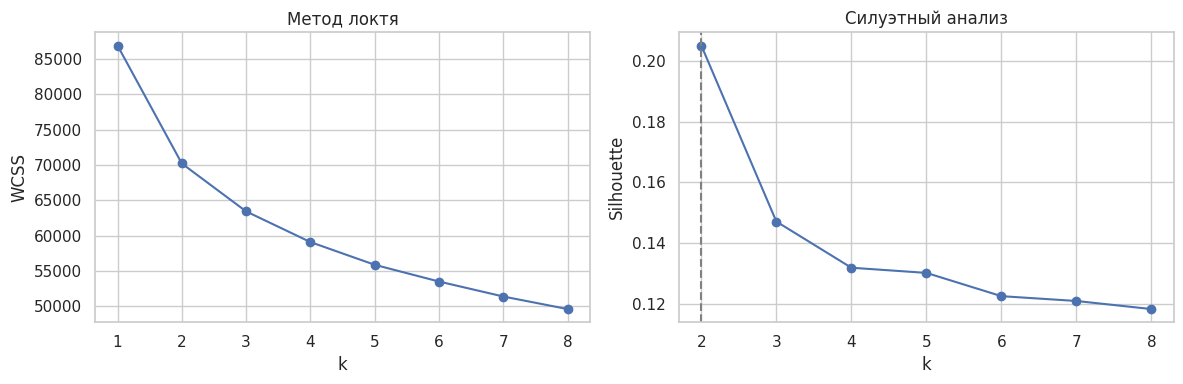

Выбрано k = 2


In [8]:
eval_idx=np.random.default_rng(42).choice(len(Z),2500,replace=False)
D_eval=pairwise_distances(Z[eval_idx]); np.fill_diagonal(D_eval,0)
k_values=range(2,9); km_models={}; rows=[]
for k in range(1,9):
    model=KMeans(n_clusters=k,n_init=10,random_state=42).fit(Z)
    km_models[k]=model
    sil=silhouette_score(D_eval,model.labels_[eval_idx],metric='precomputed') if k>1 else np.nan
    rows.append({'k':k,'WCSS':model.inertia_,'Silhouette':sil})
km_grid=pd.DataFrame(rows).set_index('k'); km_grid['Снижение WCSS, %']=-100*km_grid.WCSS.pct_change()
best_k_km=int(km_grid.Silhouette.idxmax()); labels_km=km_models[best_k_km].labels_
display(km_grid)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(km_grid.index,km_grid.WCSS,'o-'); axes[0].set(title='Метод локтя',xlabel='k',ylabel='WCSS')
axes[1].plot(km_grid.index,km_grid.Silhouette,'o-'); axes[1].axvline(best_k_km,ls='--',color='gray'); axes[1].set(title='Силуэтный анализ',xlabel='k',ylabel='Silhouette')
plt.tight_layout(); plt.show(); print('Выбрано k =',best_k_km)

### 3.2. Иерархическая агломеративная кластеризация (Ward)
Построим полное дерево с евклидовым расстоянием. Дендрограмма показывает последние 30 ветвей дерева (для читаемости, не подвыборка). Разрезы сравним по силуэту на тех же объектах.

,Silhouette
k,
2,0.187
3,0.085
4,0.088
5,0.062
6,0.052
7,0.051
8,0.040


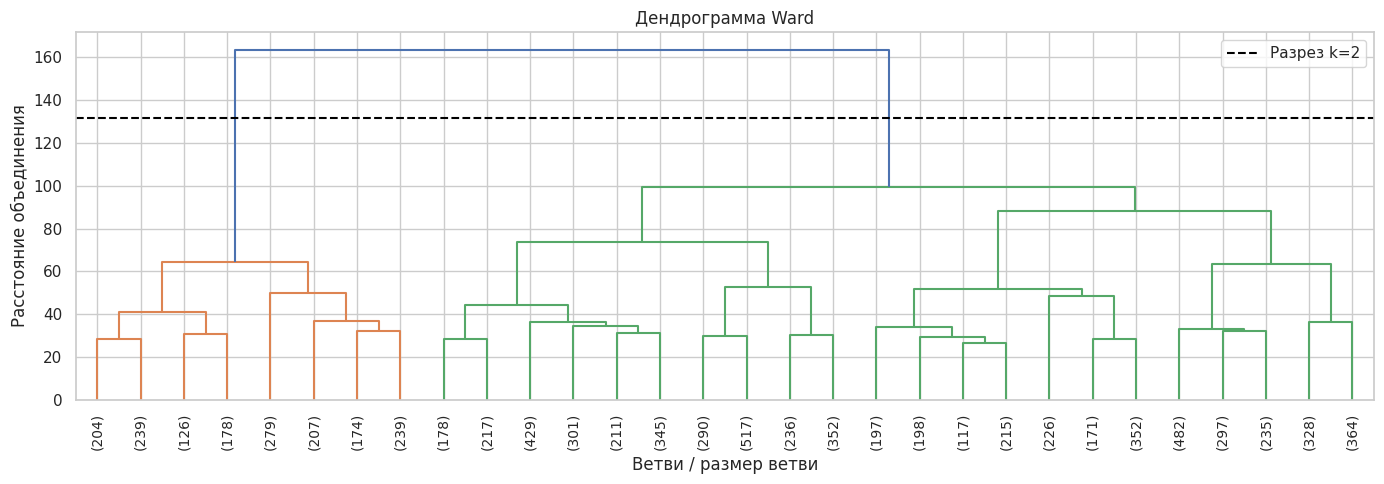

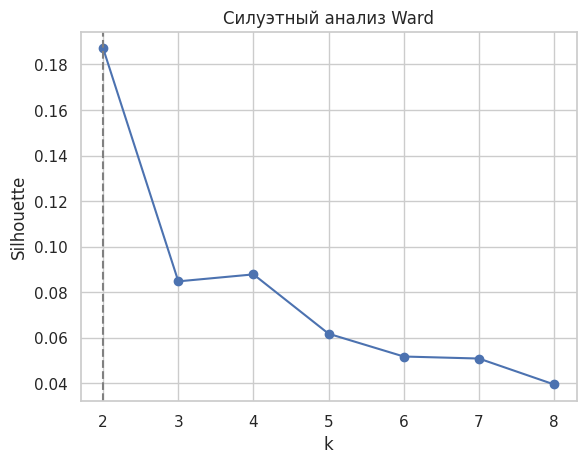

Выбрано k = 2


In [9]:
tree=linkage(Z,method='ward'); ward_labels={}; rows=[]
for k in k_values:
    lab=cut_tree(tree,n_clusters=[k]).ravel(); ward_labels[k]=lab
    rows.append({'k':k,'Silhouette':silhouette_score(D_eval,lab[eval_idx],metric='precomputed')})
ward_grid=pd.DataFrame(rows).set_index('k'); best_k_ward=int(ward_grid.Silhouette.idxmax()); labels_ward=ward_labels[best_k_ward]
display(ward_grid)
height=(tree[-best_k_ward,2]+tree[-best_k_ward+1,2])/2
fig,ax=plt.subplots(figsize=(14,5))
dendrogram(tree,truncate_mode='lastp',p=30,show_leaf_counts=True,leaf_rotation=90,color_threshold=height,ax=ax)
ax.axhline(height,color='black',ls='--',label=f'Разрез k={best_k_ward}'); ax.legend(); ax.set(title='Дендрограмма Ward',xlabel='Ветви / размер ветви',ylabel='Расстояние объединения'); plt.tight_layout(); plt.show()
plt.plot(ward_grid.index,ward_grid.Silhouette,'o-'); plt.axvline(best_k_ward,ls='--',color='gray'); plt.xlabel('k'); plt.ylabel('Silhouette'); plt.title('Силуэтный анализ Ward'); plt.show()
print('Выбрано k =',best_k_ward)

In [10]:
display(Markdown(f'**Вывод:** K-means: k={best_k_km}, силуэт {km_grid.loc[best_k_km,"Silhouette"]:.3f}; Ward: k={best_k_ward}, силуэт {ward_grid.loc[best_k_ward,"Silhouette"]:.3f}. На графике локтя WCSS постепенно уменьшается без однозначного резкого излома. Основной критерий — максимум силуэта, дендрограмма и локоть — дополнительные проверки. Низкие значения свидетельствуют о перекрытии групп.'))

**Вывод:** K-means: k=2, силуэт 0.205; Ward: k=2, силуэт 0.187. На графике локтя WCSS постепенно уменьшается без однозначного резкого излома. Основной критерий — максимум силуэта, дендрограмма и локоть — дополнительные проверки. Низкие значения свидетельствуют о перекрытии групп.

## 4. Оценка качества
Внутренние метрики: Silhouette (от −1 до 1, выше лучше), Calinski–Harabasz (межгрупповой/внутригрупповой разброс с поправкой на число кластеров, выше лучше), Davies–Bouldin (разброс относительно расстояния между центрами, ниже лучше). Финальный силуэт рассчитываем по всем 7904 объектам.

Внешние метрики: Rand, Adjusted Rand (ARI, поправка на случайность), Jaccard по парам объектов, NMI (нормализованная взаимная информация). Для Jaccard TP — пары, объединённые в обоих разбиениях; FP и FN — пары, объединённые только в одном. Метрики не зависят от нумерации групп и допускают разное число классов. Известный уровень риска — внешний ориентир, а не доказанная истинная кластерная структура.

In [11]:
def pair_jaccard(y,lab):
    tab=contingency_matrix(y,lab).astype(np.int64)
    choose2=lambda a: np.sum(a*(a-1)//2)
    tp=choose2(tab); fp=choose2(tab.sum(axis=0))-tp; fn=choose2(tab.sum(axis=1))-tp
    return tp/(tp+fp+fn) if tp+fp+fn else 1.
methods={'K-means':labels_km,'Ward':labels_ward}; rows=[]
for name,lab in methods.items():
    rows.append({'Метод':name,'k':len(np.unique(lab)), 'Silhouette':silhouette_score(Z,lab),
        'Calinski-Harabasz':calinski_harabasz_score(Z,lab),'Davies-Bouldin':davies_bouldin_score(Z,lab),
        'Rand':rand_score(y_true,lab),'ARI':adjusted_rand_score(y_true,lab),'Jaccard':pair_jaccard(y_true,lab),'NMI':normalized_mutual_info_score(y_true,lab)})
metrics=pd.DataFrame(rows).set_index('Метод'); display(metrics.round(4))
for name,lab in methods.items():
    print(name,'— уровни риска внутри групп, %'); display((pd.crosstab(lab,y_true,normalize='index')*100).round(1))

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin,Rand,ARI,Jaccard,NMI
Метод,,,,,,,,
K-means,2,0.210,1883.060,1.867,0.472,2.020e-02,0.236,0.054
Ward,2,0.197,1435.964,1.884,0.421,-8.000e-04,0.237,0.025


K-means — уровни риска внутри групп, %


crash_risk_level,Mild Afternoon Fatigue,Moderate Crash & Lethargy,Severe Crash & Tachycardia,Sustained / Negligible Crash
row_0,,,,
0,34.1,28.3,20.0,17.6
1,20.0,34.8,43.0,2.2


Ward — уровни риска внутри групп, %


crash_risk_level,Mild Afternoon Fatigue,Moderate Crash & Lethargy,Severe Crash & Tachycardia,Sustained / Negligible Crash
row_0,,,,
0,31.9,28.9,23.5,15.7
1,22.5,34.9,39.2,3.4


In [12]:
best_sil=metrics.Silhouette.idxmax(); best_ch=metrics['Calinski-Harabasz'].idxmax(); best_db=metrics['Davies-Bouldin'].idxmin(); best_ari=metrics.ARI.idxmax()
display(Markdown(f'**Интерпретация:** лучший силуэт у {best_sil} ({metrics.loc[best_sil,"Silhouette"]:.3f}), лучший CH у {best_ch} ({metrics.loc[best_ch,"Calinski-Harabasz"]:.1f}), минимальный DB у {best_db} ({metrics.loc[best_db,"Davies-Bouldin"]:.3f}). Силуэты далеки от 1: группы перекрываются. Наибольший ARI с риском у {best_ari} ({metrics.loc[best_ari,"ARI"]:.3f}); малые ARI означают слабое согласие с категориями риска. Rand учитывает также множество пар, раздельных в обоих разбиениях; Jaccard оценивает совпадение объединённых пар, NMI — общую информацию. Разбиение не следует считать классификатором риска.'))

**Интерпретация:** лучший силуэт у K-means (0.210), лучший CH у K-means (1883.1), минимальный DB у K-means (1.867). Силуэты далеки от 1: группы перекрываются. Наибольший ARI с риском у K-means (0.020); малые ARI означают слабое согласие с категориями риска. Rand учитывает также множество пар, раздельных в обоих разбиениях; Jaccard оценивает совпадение объединённых пар, NMI — общую информацию. Разбиение не следует считать классификатором риска.

### 4.1. Расстояния и компактность
В стандартизованном пространстве вычислим центры, расстояния между центрами, средний радиус (среднее расстояние до центра), RMS-радиус и WCSS. Средние попарные расстояния внутри и между группами оцениваем на общей подвыборке 2500 объектов; центры и радиусы — на всей очищенной выборке.

In [13]:
geometry={}
for name,lab in methods.items():
    ids=np.unique(lab); centers=np.vstack([Z[lab==i].mean(axis=0) for i in ids]); rows=[]
    for i,center in zip(ids,centers):
        pts=Z[lab==i]; d=np.linalg.norm(pts-center,axis=1); sampled=Z[eval_idx][lab[eval_idx]==i]
        rows.append({'Кластер':i,'Размер':len(pts),'Доля, %':100*len(pts)/len(Z),'Средний радиус':d.mean(),'RMS-радиус':np.sqrt(np.mean(d*d)),'WCSS':np.sum(d*d),'Среднее попарное внутри':pdist(sampled).mean()})
    table=pd.DataFrame(rows).set_index('Кластер'); between=pd.DataFrame(squareform(pdist(centers)),index=ids,columns=ids)
    mask=lab[eval_idx][:,None]!=lab[eval_idx][None,:]; inter=D_eval[mask].mean()
    geometry[name]=(table,between,inter,centers)
    print(name); display(table.round(3)); print('Расстояния между центрами:'); display(between.round(3))
    print(f'Среднее попарное между группами: {inter:.3f}; общая WCSS: {table.WCSS.sum():.2f}')
    display(Markdown(f'Средневзвешенный радиус: {np.average(table["Средний радиус"],weights=table["Размер"]):.3f}; межкластерное расстояние {inter:.3f} сравниваем с попарными внутригрупповыми расстояниями в таблице. Больший разрыв означает более выраженную структуру; низкий силуэт показывает, что перекрытие сохраняется.'))

K-means


,Размер,"Доля, %",Средний радиус,RMS-радиус,WCSS,Среднее попарное внутри
Кластер,,,,,,
0,5577,70.559,2.799,2.867,45842.224,3.960
1,2327,29.441,3.161,3.236,24370.071,4.403


Расстояния между центрами:


,0,1
0,0.000,3.192
1,3.192,0.000


Среднее попарное между группами: 5.194; общая WCSS: 70212.29


Средневзвешенный радиус: 2.906; межкластерное расстояние 5.194 сравниваем с попарными внутригрупповыми расстояниями в таблице. Больший разрыв означает более выраженную структуру; низкий силуэт показывает, что перекрытие сохраняется.

... (2 outputs left out)

Расстояния между центрами:


,0,1
0,0.000,3.203
1,3.203,0.000


Среднее попарное между группами: 5.202; общая WCSS: 73574.01


Средневзвешенный радиус: 2.971; межкластерное расстояние 5.202 сравниваем с попарными внутригрупповыми расстояниями в таблице. Больший разрыв означает более выраженную структуру; низкий силуэт показывает, что перекрытие сохраняется.

## 5. Влияние параметров и устойчивость
### 5.1. Влияние k на K-means
Проверяем WCSS, силуэт, CH, DB и минимальную долю группы. Увеличение k уменьшает оптимальную WCSS, но не обязательно улучшает разделение.

,WCSS,Silhouette,"Снижение WCSS, %",CH,DB,"Минимальная доля, %"
k,,,,,,
2,70212.320,0.205,19.244,1883.060,1.867,29.441
3,63418.950,0.147,9.675,1465.430,2.075,22.204
4,59067.585,0.132,6.861,1242.780,2.105,16.511
5,55846.433,0.130,5.453,1099.624,1.954,13.942
6,53471.474,0.122,4.253,988.816,1.981,10.868
7,51349.024,0.121,3.969,912.363,1.912,10.362
8,49568.780,0.118,3.467,850.521,1.887,8.844


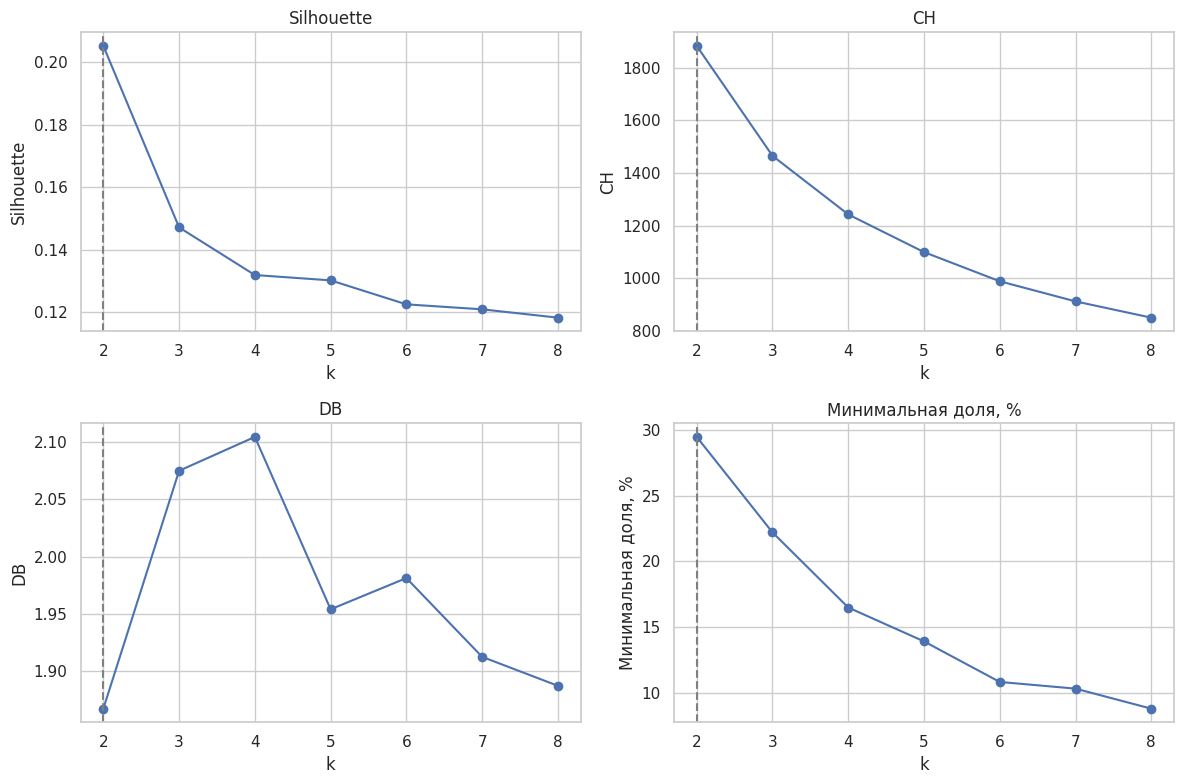

In [14]:
sensitivity=km_grid.loc[2:8].copy()
for k in k_values:
    lab=km_models[k].labels_
    sensitivity.loc[k,'CH']=calinski_harabasz_score(Z,lab)
    sensitivity.loc[k,'DB']=davies_bouldin_score(Z,lab)
    sensitivity.loc[k,'Минимальная доля, %']=100*np.bincount(lab).min()/len(lab)
display(sensitivity.round(3))
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,['Silhouette','CH','DB','Минимальная доля, %']):
    ax.plot(sensitivity.index,sensitivity[col],'o-'); ax.axvline(best_k_km,ls='--',color='gray'); ax.set(title=col,xlabel='k',ylabel=col)
plt.tight_layout(); plt.show()

**Вывод:** после k=2 силуэт снижается, несмотря на уменьшение WCSS. Дополнительные центры преимущественно дробят перекрывающиеся группы, а не формируют отчётливые новые профили. Оставляем k по максимуму силуэта, не используя классы риска для выбора.

### 5.2. Устойчивость групп
Пять повторов на случайных 80% данных. В каждом повторе заново обучаем StandardScaler и оба алгоритма с выбранными k. ARI между исходным и новым разбиением на общих объектах: 1 — совпадение, около 0 — случайное согласие. Также проверяем эффект удаления экстремальных наблюдений для K-means.

In [15]:
rows=[]
for repeat in range(5):
    idx=np.random.default_rng(42+repeat).choice(len(Z),int(.8*len(Z)),replace=False)
    z_sub=StandardScaler().fit_transform(X.iloc[idx])
    km_sub=KMeans(n_clusters=best_k_km,n_init=10,random_state=42+repeat).fit_predict(z_sub)
    ward_sub=cut_tree(linkage(z_sub,method='ward'),n_clusters=[best_k_ward]).ravel()
    rows.append({'Повтор':repeat+1,'K-means':adjusted_rand_score(labels_km[idx],km_sub),'Ward':adjusted_rand_score(labels_ward[idx],ward_sub)})
stability=pd.DataFrame(rows).set_index('Повтор'); display(stability); display(stability.agg(['mean','std']))
ari_methods=adjusted_rand_score(labels_km,labels_ward)
print('ARI между методами:',round(ari_methods,4))
lab_all=KMeans(n_clusters=best_k_km,n_init=10,random_state=42).fit_predict(StandardScaler().fit_transform(raw))
ari_filter=adjusted_rand_score(labels_km,lab_all[keep.to_numpy()]); print('ARI K-means с фильтрацией и без:',round(ari_filter,4))
stable_winner=stability.mean().idxmax()
display(Markdown(f'**Устойчивость:** средний ARI K-means = {stability["K-means"].mean():.3f}, Ward = {stability.Ward.mean():.3f}. Устойчивее {stable_winner}. ARI между методами = {ari_methods:.3f}; ARI при проверке фильтрации = {ari_filter:.3f} (чем ближе к 1, тем меньше её влияние). Эксперимент ограничен выбранными k и пятью повторами.'))

,K-means,Ward
Повтор,,
1,0.990,0.492
2,0.995,0.523
3,0.988,0.585
4,0.994,0.348
5,0.990,0.558


,K-means,Ward
mean,0.991,0.501
std,0.003,0.092


ARI между методами: 0.5114
ARI K-means с фильтрацией и без: 0.8607


**Устойчивость:** средний ARI K-means = 0.991, Ward = 0.501. Устойчивее K-means. ARI между методами = 0.511; ARI при проверке фильтрации = 0.861 (чем ближе к 1, тем меньше её влияние). Эксперимент ограничен выбранными k и пятью повторами.

## 6. Визуализация и интерпретация
### 6.1. PCA
PCA используется только для визуализации, кластеризация проведена в полном 11-мерном пространстве. Покажем долю объяснённой дисперсии и центры.

Доли дисперсии: [0.2843 0.1335]
Суммарно: 41.77%


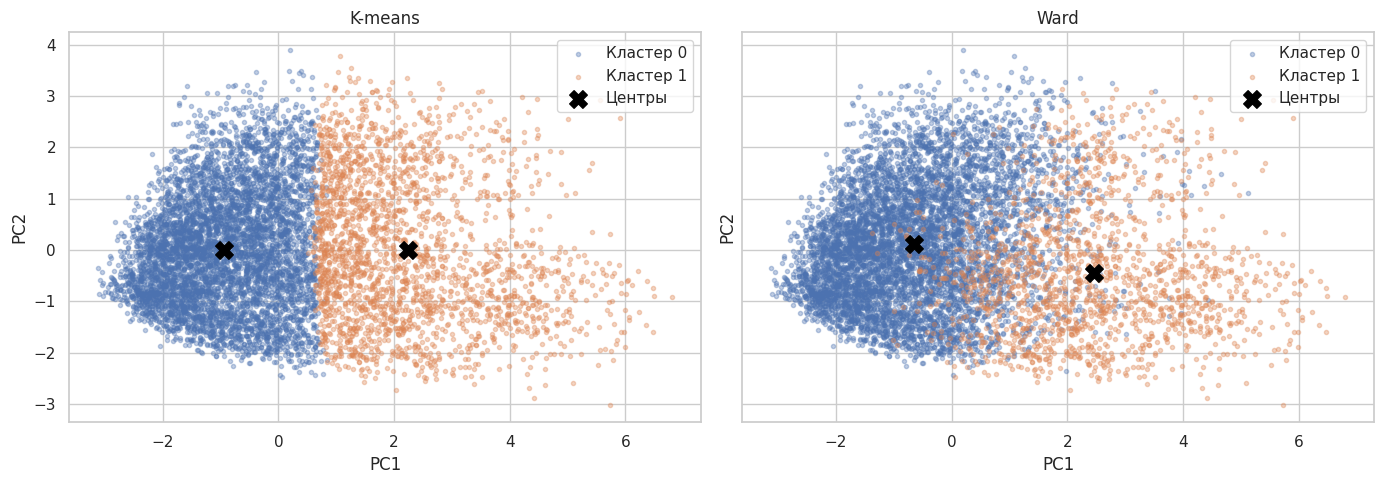

,PC1,PC2
age,0.006,-0.023
baseline_anxiety_score,0.093,-0.038
prior_sleep_hours,-0.088,-0.136
daily_hydration_liters,-0.056,0.084
caffeine_mg,0.383,-0.278
sugar_grams,-0.021,0.673
consumption_duration_min,-0.198,0.012
heart_rate_spike_bpm,0.459,-0.068
jitters_intensity_score,0.525,0.008
acute_anxiety_score,0.512,0.013


In [16]:
pca=PCA(n_components=2); P=pca.fit_transform(Z)
print('Доли дисперсии:',pca.explained_variance_ratio_.round(4)); print(f'Суммарно: {pca.explained_variance_ratio_.sum():.2%}')
fig,axes=plt.subplots(1,2,figsize=(14,5),sharex=True,sharey=True)
for ax,(name,lab) in zip(axes,methods.items()):
    for i in np.unique(lab): ax.scatter(P[lab==i,0],P[lab==i,1],s=9,alpha=.35,label=f'Кластер {i}')
    pc=pca.transform(geometry[name][3]); ax.scatter(pc[:,0],pc[:,1],marker='X',s=160,c='black',label='Центры')
    ax.set(title=name,xlabel='PC1',ylabel='PC2'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(pca.components_.T,index=features,columns=['PC1','PC2']).round(3))

Проекции показывают градиент выраженности реакции, а не полностью отделённые облака. Перекрытие соответствует невысокому силуэту; часть информации потеряна при переходе к двум измерениям.

### 6.2. Центры и профили групп
Средние по исходным признакам и по тяжести спада (только для интерпретации). Для Ward центры вычисляются после разбиения. Дополнительно рассмотрим наиболее частые категориальные значения.

K-means — центры в исходных единицах


cluster,0,1
age,32.74,33.37
baseline_anxiety_score,3.36,3.80
prior_sleep_hours,6.47,6.15
daily_hydration_liters,2.16,2.00
caffeine_mg,175.79,246.42
sugar_grams,18.87,16.57
consumption_duration_min,32.42,21.49
heart_rate_spike_bpm,2.89,8.21
jitters_intensity_score,2.12,5.95
acute_anxiety_score,2.50,6.29


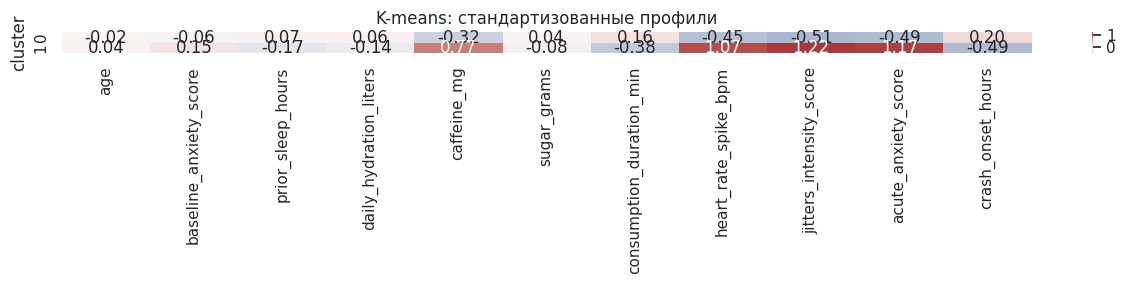

,cyp1a2_metabolizer_type
cluster,
0,Normal
1,Normal


,caffeine_tolerance
cluster,
0,Moderate
1,Moderate


,primary_caffeine_source
cluster,
0,Brewed Drip Coffee
1,Energy Drink (Sugar-Free)


**Кластер 0 — менее выраженная реакция относительно выборки** (n=5577). Доза: 175.8 мг; дрожь: 2.12; острая тревожность: 2.50; прирост ЧСС: 2.89 уд/мин; сон: 6.47 ч; тяжесть спада: 5.79. Наиболее повышены: crash_onset_hours (+0.20σ), consumption_duration_min (+0.16σ), prior_sleep_hours (+0.07σ); понижены: jitters_intensity_score (-0.51σ), acute_anxiety_score (-0.49σ), heart_rate_spike_bpm (-0.45σ).

**Кластер 1 — повышенная реакция относительно выборки** (n=2327). Доза: 246.4 мг; дрожь: 5.95; острая тревожность: 6.29; прирост ЧСС: 8.21 уд/мин; сон: 6.15 ч; тяжесть спада: 7.45. Наиболее повышены: jitters_intensity_score (+1.22σ), acute_anxiety_score (+1.17σ), heart_rate_spike_bpm (+1.07σ); понижены: crash_onset_hours (-0.49σ), consumption_duration_min (-0.38σ), prior_sleep_hours (-0.17σ).

Ward — центры в исходных единицах


cluster,0,1
age,33.02,32.59
baseline_anxiety_score,3.53,3.31
prior_sleep_hours,6.39,6.31
daily_hydration_liters,2.16,1.92
caffeine_mg,179.81,260.36
sugar_grams,20.33,10.07
consumption_duration_min,31.16,21.74
heart_rate_spike_bpm,3.24,9.07
jitters_intensity_score,2.45,6.27
acute_anxiety_score,2.91,6.30


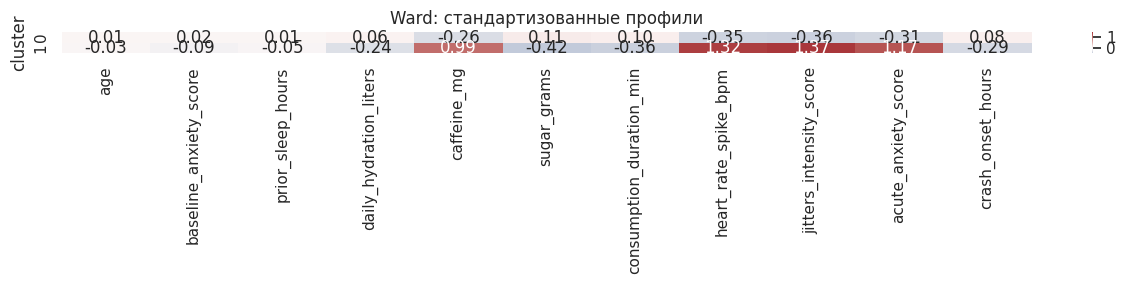

,cyp1a2_metabolizer_type
cluster,
0,Normal
1,Normal


,caffeine_tolerance
cluster,
0,Moderate
1,Low


,primary_caffeine_source
cluster,
0,Brewed Drip Coffee
1,Energy Drink (Sugar-Free)


**Кластер 0 — менее выраженная реакция относительно выборки** (n=6258). Доза: 179.8 мг; дрожь: 2.45; острая тревожность: 2.91; прирост ЧСС: 3.24 уд/мин; сон: 6.39 ч; тяжесть спада: 6.02. Наиболее повышены: sugar_grams (+0.11σ), consumption_duration_min (+0.10σ), crash_onset_hours (+0.08σ); понижены: jitters_intensity_score (-0.36σ), heart_rate_spike_bpm (-0.35σ), acute_anxiety_score (-0.31σ).

**Кластер 1 — повышенная реакция относительно выборки** (n=1646). Доза: 260.4 мг; дрожь: 6.27; острая тревожность: 6.30; прирост ЧСС: 9.07 уд/мин; сон: 6.31 ч; тяжесть спада: 7.27. Наиболее повышены: jitters_intensity_score (+1.37σ), heart_rate_spike_bpm (+1.32σ), acute_anxiety_score (+1.17σ); понижены: sugar_grams (-0.42σ), consumption_duration_min (-0.36σ), crash_onset_hours (-0.29σ).

In [17]:
profiles={}
for name,lab in methods.items():
    prof=clean.assign(cluster=lab).groupby('cluster')[features+['crash_severity_score']].mean(); profiles[name]=prof
    print(name,'— центры в исходных единицах'); display(prof.T.round(2))
    centers_orig=scaler.inverse_transform(geometry[name][3]); assert np.allclose(centers_orig,prof[features].to_numpy())
    zcent=pd.DataFrame(geometry[name][3],columns=features,index=prof.index)
    plt.figure(figsize=(13,3)); sns.heatmap(zcent,annot=True,fmt='.2f',cmap='vlag',center=0); plt.title(name+': стандартизованные профили'); plt.tight_layout(); plt.show()
    for col in ['cyp1a2_metabolizer_type','caffeine_tolerance','primary_caffeine_source']:
        display(clean.assign(cluster=lab).groupby('cluster')[col].agg(lambda s:s.mode().iloc[0]).to_frame())
    for i,row in prof.iterrows():
        high=', '.join(f'{f} ({v:+.2f}σ)' for f,v in zcent.loc[i].nlargest(3).items() if v>0)
        low=', '.join(f'{f} ({v:+.2f}σ)' for f,v in zcent.loc[i].nsmallest(3).items() if v<0)
        reaction='повышенная реакция' if row.jitters_intensity_score>X.jitters_intensity_score.mean() else 'менее выраженная реакция'
        display(Markdown(f'**Кластер {i} — {reaction} относительно выборки** (n={sum(lab==i)}). Доза: {row.caffeine_mg:.1f} мг; дрожь: {row.jitters_intensity_score:.2f}; острая тревожность: {row.acute_anxiety_score:.2f}; прирост ЧСС: {row.heart_rate_spike_bpm:.2f} уд/мин; сон: {row.prior_sleep_hours:.2f} ч; тяжесть спада: {row.crash_severity_score:.2f}. Наиболее повышены: {high or "нет"}; понижены: {low or "нет"}.'))

### 6.3. Сравнение результатов

In [18]:
summary=metrics.copy(); summary['WCSS']=[geometry[name][0].WCSS.sum() for name in summary.index]; summary['Средний ARI устойчивости']=stability.mean()
display(summary.round(4)); display(pd.crosstab(labels_km,labels_ward,rownames=['K-means'],colnames=['Ward']))
display(Markdown(f"""## Заключение
1. Исследованы {len(df)} объектов и {df.shape[1]} столбцов, без пропусков и дубликатов. После фильтрации осталось {len(X)} объектов. Использовано {len(features)} числовых признаков без метки риска и тяжести спада.
2. Выполнены стандартизация, анализ распределений и корреляций, матрица рассеивания. Явно изолированные группы не выявлены.
3. Подобраны параметры K-means (k={best_k_km}, n_init=10) и Ward (k={best_k_ward}). Использованы локоть, силуэт и дендрограмма.
4. K-means: Silhouette={metrics.loc['K-means','Silhouette']:.3f}, CH={metrics.loc['K-means','Calinski-Harabasz']:.1f}, ARI с риском={metrics.loc['K-means','ARI']:.3f}. Ward: Silhouette={metrics.loc['Ward','Silhouette']:.3f}, CH={metrics.loc['Ward','Calinski-Harabasz']:.1f}, ARI с риском={metrics.loc['Ward','ARI']:.3f}. По силуэту предпочтительнее {best_sil}, по устойчивости — {stable_winner}. Низкие силуэты означают слабое разделение, поэтому нельзя утверждать, что выделены однозначные природные классы.
5. Группы различаются выраженностью реакции и дозировкой кофеина. Низкое согласие с классами риска означает, что профили реакции не тождественны категориям тяжести. PCA сохраняет {pca.explained_variance_ratio_.sum():.1%} дисперсии.
6. Ограничения: исключены категориальные признаки и экстремальные наблюдения, коррелирующие показатели могут повышать вес реакции; происхождение данных неизвестно. В дальнейшем можно проверить GMM, альтернативный набор признаков и методы для смешанных данных.

**Цель работы достигнута:** проведены кластеризация двумя методами, подбор параметров, оценка качества, исследование устойчивости, визуализация и содержательная интерпретация результатов."""))

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin,Rand,ARI,Jaccard,NMI,WCSS,Средний ARI устойчивости
Метод,,,,,,,,,,
K-means,2,0.210,1883.060,1.867,0.472,2.020e-02,0.236,0.054,70212.295,0.991
Ward,2,0.197,1435.964,1.884,0.421,-8.000e-04,0.237,0.025,73574.012,0.501


Ward,0,1
K-means,,
0,5393,184
1,865,1462


## Заключение
1. Исследованы 8000 объектов и 18 столбцов, без пропусков и дубликатов. После фильтрации осталось 7904 объектов. Использовано 11 числовых признаков без метки риска и тяжести спада.
2. Выполнены стандартизация, анализ распределений и корреляций, матрица рассеивания. Явно изолированные группы не выявлены.
3. Подобраны параметры K-means (k=2, n_init=10) и Ward (k=2). Использованы локоть, силуэт и дендрограмма.
4. K-means: Silhouette=0.210, CH=1883.1, ARI с риском=0.020. Ward: Silhouette=0.197, CH=1436.0, ARI с риском=-0.001. По силуэту предпочтительнее K-means, по устойчивости — K-means. Низкие силуэты означают слабое разделение, поэтому нельзя утверждать, что выделены однозначные природные классы.
5. Группы различаются выраженностью реакции и дозировкой кофеина. Низкое согласие с классами риска означает, что профили реакции не тождественны категориям тяжести. PCA сохраняет 41.8% дисперсии.
6. Ограничения: исключены категориальные признаки и экстремальные наблюдения, коррелирующие показатели могут повышать вес реакции; происхождение данных неизвестно. В дальнейшем можно проверить GMM, альтернативный набор признаков и методы для смешанных данных.

**Цель работы достигнута:** проведены кластеризация двумя методами, подбор параметров, оценка качества, исследование устойчивости, визуализация и содержательная интерпретация результатов.